In [1]:
import hashlib
import os
import platform
import uuid
import sys
# 后面需要用到的库
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 修改为你自己的学号
STUDENT_ID = 20244080126

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python]   {sys.version.split()[0]}")


[Conda 环境] exp01
[学号]      20244080126
[机器指纹] 759a8a296917ae29
[RUN_ID]   20244080126-759a8a296917ae29
[Python]   3.10.22


In [2]:
# 任务1：wigner_density(x) 半圆密度函数
# 公式：
# f(x) = 1/(2π) * sqrt(4-x²) , |x| ≤ 2
# f(x) = 0                   , |x| > 2
# 要求：必须使用numpy.sqrt，不能用math.sqrt；同时支持数字和numpy数组输入
def wigner_density(x):
    x = np.asarray(x)   # 统一转成numpy数组，兼容单个数字和数组
    res = np.zeros_like(x, dtype=float)
    # 只在满足 |x| <= 2 的位置计算平方根，避免负数开根号
    mask = np.abs(x) <= 2
    res[mask] = (1 / (2 * np.pi)) * np.sqrt(4 - x[mask] ** 2)
    # 如果输入是单个数字，返回float；数组则返回数组
    if x.ndim == 0:
        return float(res)
    return res

# 测试示例
print("wigner_density(0):", wigner_density(0))
print("wigner_density(3):", wigner_density(3))


wigner_density(0): 0.3183098861837907
wigner_density(3): 0.0


In [3]:
#任务2：generate_wigner(n) 生成Wigner对称矩阵
# 规则：
# 1. n阶方阵，上三角（含对角线）元素独立服从 N(0, 1/n)
# 2. 对称：Zji = Zij
# 3. 输入非法（不是正整数）抛出异常
def generate_wigner(n):
    # 类型合法性校验
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须是正整数！")
    # 生成n*n标准正态，方差1/n
    mat = np.random.normal(loc=0, scale=np.sqrt(1/n), size=(n, n))
    # 构造对称矩阵，上三角+转置下三角，对角线不会重复叠加
    mat = np.triu(mat) + np.triu(mat, k=1).T
    return mat

# 测试
test_mat = generate_wigner(5)
print("5阶Wigner矩阵：\n", test_mat)


5阶Wigner矩阵：
 [[-0.36689377 -0.10097721 -0.4361092   0.40976586 -0.15803524]
 [-0.10097721 -0.05151762  0.94026349  0.30975876  0.03558198]
 [-0.4361092   0.94026349  0.49786671  0.76067191  1.06717637]
 [ 0.40976586  0.30975876  0.76067191  0.52190957  0.20705443]
 [-0.15803524  0.03558198  1.06717637  0.20705443 -0.7819135 ]]


In [4]:
#任务3：get_spectrum(matrix) 求特征值，非递增排序
# 输入numpy矩阵，返回全部特征值，从大到小排序
def get_spectrum(matrix):
    # np.linalg.eigvalsh：专门求对称实矩阵特征值，速度更快
    eigvals = np.linalg.eigvalsh(matrix)
    # 非递减 → 反转，变成非递增
    eigvals_sorted = np.sort(eigvals)[::-1]
    return eigvals_sorted

# 测试
eig = get_spectrum(test_mat)
print("特征值（降序）：", eig)


特征值（降序）： [ 2.03652378  0.45926551 -0.3272514  -0.77815544 -1.57093107]


C:\Users\15243\AppData\Local\Temp\ipykernel_6888\2228153656.py:21: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
D:\Anaconda\envs\exp01\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


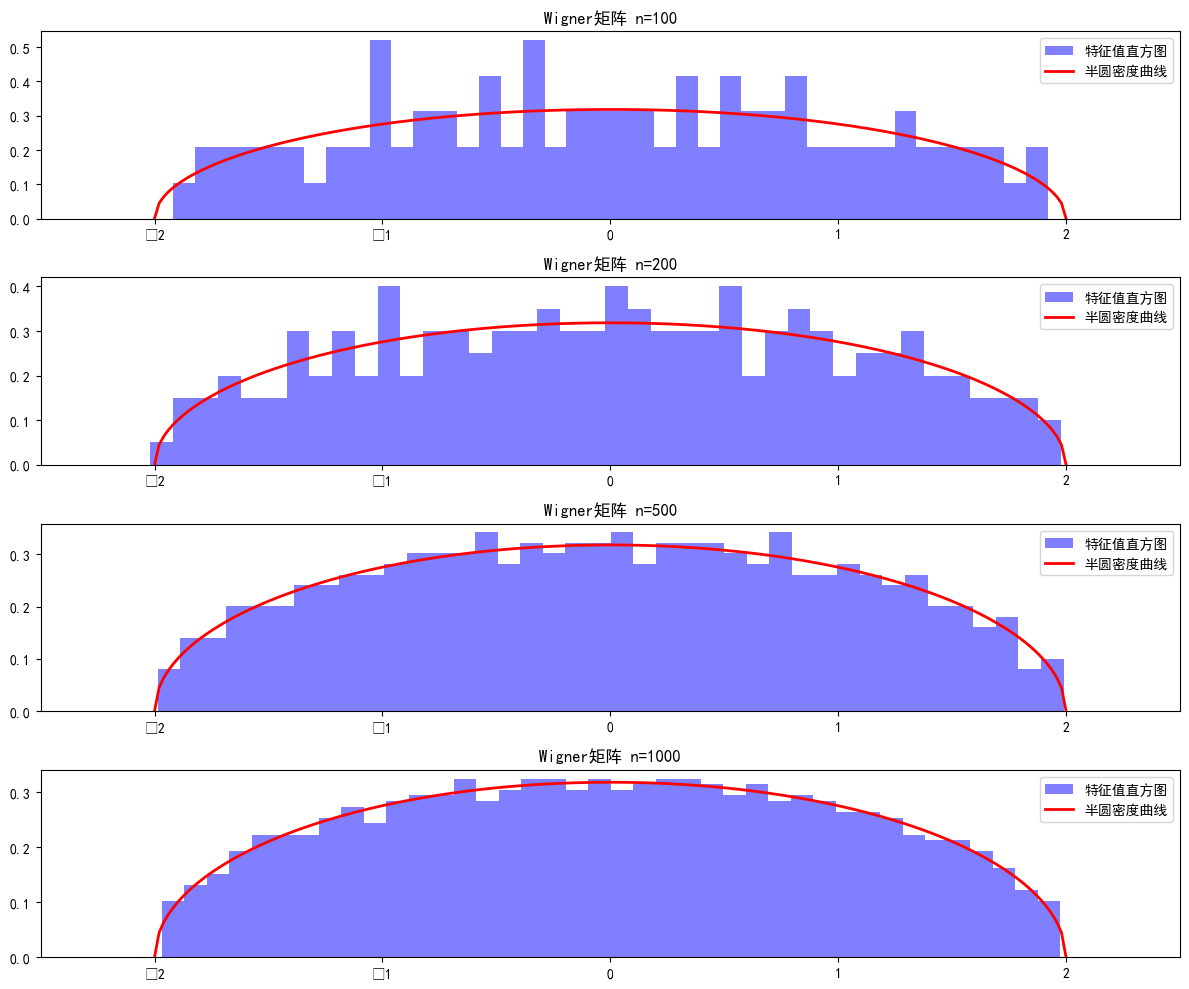

In [5]:
#任务4：绘图，4个子图 n=100,200,500,1000
# 蓝色：标准化直方图；红色：半圆密度曲线
# 结论：n越大，拟合越好，一般n=500左右就已经拟合得比较不错，n=1000拟合效果很好
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.figure(figsize=(12,10))
n_list = [100, 200, 500, 1000]

for idx, n in enumerate(n_list):
    plt.subplot(4, 1, idx+1)
    w_mat = generate_wigner(n)
    eig_vals = get_spectrum(w_mat)
    # 直方图 density=True 标准化为概率密度
    plt.hist(eig_vals, bins=40, density=True, color="blue", alpha=0.5, label="特征值直方图")
    # 画理论半圆曲线
    x_line = np.linspace(-2, 2, 200)
    y_line = wigner_density(x_line)
    plt.plot(x_line, y_line, c="red", lw=2, label="半圆密度曲线")
    plt.title(f"Wigner矩阵 n={n}")
    plt.xlim(-2.5,2.5)
    plt.legend()
plt.tight_layout()
plt.show()


In [6]:
#实验二 Conway生命游戏
#任务1：is_valid_board(board) 判断棋盘是否合法
# 合法条件：二维ndarray，所有元素只能是0或者1
def is_valid_board(board):
    # 判断是不是numpy数组、是不是二维
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    # 判断所有元素只能是0或1
    unique_vals = np.unique(board)
    return set(unique_vals).issubset({0,1})

# 测试
test_board = np.array([[1,0,0],[0,1,0]])
print("是否合法棋盘：", is_valid_board(test_board))


是否合法棋盘： True


In [7]:
#任务2：gol_step(board) 一步演化，环绕边界
# 规则：
# 活细胞(1)：邻居<2 死亡；邻居=2/3存活；邻居>3死亡
# 死细胞(0)：邻居=3复活，其余保持死亡
# np.roll 自动实现环绕边界，向右/向下滚动，超出边缘从另一边回来
def gol_step(board):
    # 第一步：先校验棋盘合法性，不合法抛异常
    if not is_valid_board(board):
        raise ValueError("输入不是合法生命游戏棋盘！")
    # 统计8方向邻居总数
    neighbor_count = np.zeros_like(board, dtype=int)
    # 8个偏移方向，排除(0,0)自身
    for dr in (-1,0,1):
        for dc in (-1,0,1):
            if dr == 0 and dc == 0:
                continue
            # np.roll：沿着轴滚动，自动环形环绕
            neighbor_count += np.roll(np.roll(board, dr, axis=0), dc, axis=1)
    # 生成新棋盘
    new_board = np.zeros_like(board)
    # 活细胞存活条件：本身是1，邻居是2或3
    alive_survive = (board == 1) & ((neighbor_count == 2) | (neighbor_count == 3))
    # 死细胞复活条件：本身是0，邻居=3
    dead_birth = (board == 0) & (neighbor_count == 3)
    new_board[alive_survive] = 1
    new_board[dead_birth] = 1
    return new_board

# 测试：滑翔机
glider = np.array([[0,1,0],[0,0,1],[1,1,1]])
print("原始棋盘：\n", glider)
next_board = gol_step(glider)
print("演化一步：\n", next_board)


原始棋盘：
 [[0 1 0]
 [0 0 1]
 [1 1 1]]
演化一步：
 [[0 0 0]
 [0 0 0]
 [0 0 0]]


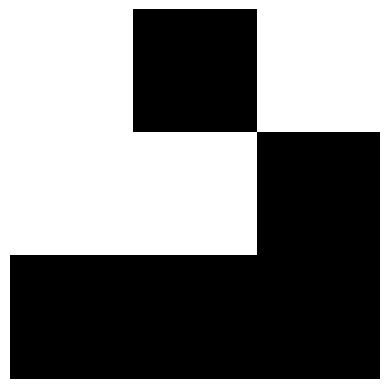

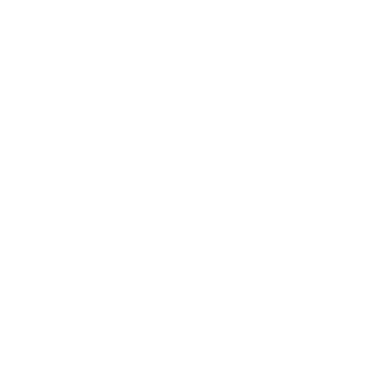

In [8]:
#任务3：draw_gol_board(board) 绘制棋盘
# 要求：活细胞黑色，死细胞白色；隐藏坐标轴、刻度、网格线
def draw_gol_board(board):
    plt.figure()
    # cmap：0=白色，1=黑色
    plt.imshow(board, cmap="binary", vmin=0, vmax=1)
    # 关闭坐标轴、刻度
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

# 测试绘图
draw_gol_board(glider)
draw_gol_board(next_board)


In [13]:
#实验三 使用pandas dataframe
import pandas as pd
# 读取你本地下载的这个csv
df = pd.read_csv("iris.csv")
# 删掉多余的Unnamed:0
df = df.drop(columns=["Unnamed: 0"])
# 重命名列
df.rename(columns={
    "sepal length (cm)": "sepal_length",
    "sepal width (cm)": "sepal_width",
    "petal length (cm)": "petal_length",
    "petal width (cm)": "petal_width"
}, inplace=True)

# 手动添加species列
species_list = ["setosa"]*50 + ["versicolor"]*50 + ["virginica"]*50
df["species"] = species_list

print(df.columns.tolist())
print(df.head())


['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [14]:
#任务2：修改索引34（第35行）、索引37（第38行）
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("修改后 索引34：")
print(df.loc[34])
print("\n修改后 索引37：")
print(df.loc[37])


修改后 索引34：
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修改后 索引37：
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object


In [15]:
#任务3：新增两个比例列
# Petal.Ratio = petal_length / petal_width
# Sepal.Ratio = sepal_length / sepal_width
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print("新增比例列后的前5行：")
print(df.head())


新增比例列后的前5行：
   sepal_length  sepal_width  petal_length  petal_width species  Petal.Ratio  \
0           5.1          3.5           1.4          0.2  setosa          7.0   
1           4.9          3.0           1.4          0.2  setosa          7.0   
2           4.7          3.2           1.3          0.2  setosa          6.5   
3           4.6          3.1           1.5          0.2  setosa          7.5   
4           5.0          3.6           1.4          0.2  setosa          7.0   

   Sepal.Ratio  
0     1.457143  
1     1.633333  
2     1.468750  
3     1.483871  
4     1.388889  


In [17]:
#任务4：保存修正后的文件
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv")


已保存 iris_corrected.csv


In [18]:
#任务5：分组聚合统计
agg_result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("分组统计结果：")
print(agg_result)


分组统计结果：
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
